# Practice: Catching a cheater

A hypothesis-testing practice problem for classes 17–19. It is not graded.

**How to use it with BoodleBox.** Work through the parts below in this notebook, running your code. When you finish a part, open the BoodleBox bot **YData Practice: Catching a Cheater (notebook)** and paste in **your code, what it printed, and your written answers** for that part. The bot compares your work with the class templates (mainly the left-handed lawyers test in class 18) and tells you what is right and what to fix. Paste one part at a time.

*Adapted from UC Berkeley's Data 8, "Catching Cheaters" (CC BY-NC 4.0).*

In [1]:
# Run this cell first.

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


# The function from class 17: flips a coin n times, where each flip lands heads with
# probability prob, and returns the number of heads (or the proportion, if return_prop = True).

def flip_coins(n, prob, return_prop = False):

    rand_nums = np.random.rand(n)
    num_heads = np.sum(rand_nums <= prob)

    if return_prop:
        return num_heads/n
    else:
        return num_heads

## The problem

A casino runs a simple game. The dealer flips a fair coin. The customer **wins \$9** if it lands heads and **loses \$10** if it lands tails.

One customer plays **20 games and wins 13** of them. The casino manager suspects that this customer is cheating: that their chance of winning a game is higher than it should be.

## Part 1. The game

**(a)** If an honest customer plays the game twice, what is the chance that they make money overall? Explain in one or two sentences.

**(b)** Check your answer with a simulation. Use `flip_coins()` and a for loop to simulate 10,000 honest customers who each play 2 games, and save each customer's number of wins in a list called `two_game_wins`. Then compute the proportion of customers who made money, and save it in `prop_made_money`.

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: (a) 1/4. A customer makes money only by winning both games (+\$18); one win and one loss is \$9 − \$10 = −\$1, and two losses is −\$20. Each game is won with probability 1/2, so both are won with probability 1/2 × 1/2 = 1/4.</font>
<!-- END SOLUTION -->

In [2]:
# Answer (b):

### BEGIN SOLUTION
two_game_wins = []

for i in range(10000):
    two_game_wins.append(flip_coins(2, 0.5))

prop_made_money = np.mean(np.array(two_game_wins) == 2)
### END SOLUTION

prop_made_money

np.float64(0.2472)

## Part 2. Step 1: State the null and alternative hypotheses

Say in words what $\pi$ stands for here. Then state the null and alternative hypotheses **in words** and **in symbols**, as in class.

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: $\pi$ is the customer's long-run chance of winning one game (not 13/20, which is the observed statistic).

**In words.** Null hypothesis: the customer is not cheating; they win each game with probability 50%, like anyone else. Alternative hypothesis: the customer is cheating; they win each game with probability higher than 50%.

**In symbols.** $H_0$: $\pi = 0.5$ &nbsp;&nbsp; $H_A$: $\pi > 0.5$</font>
<!-- END SOLUTION -->

## Part 3. Step 2: Calculate the observed statistic

**(a)** Which of these would be reasonable test statistics for this question, and why? (a) whether there is at least one win; (b) whether there is at least one loss; (c) the number of wins; (d) the number of wins minus the number of losses; (e) the total money the customer won; (f) how far the number of wins is from 10, in either direction.

**(b)** Use the number of wins as the statistic. Save the observed value in `obs_stat`.

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: (c), (d) and (e). They move together (wins minus losses is 2 × wins − 20, and money won is 19 × wins − 200), so they all put customers in the same order. (f) ignores direction: 7 wins and 13 wins count the same, so it would suit a two-sided test, not "higher than". (a) and (b) are almost always true in 20 games, so they tell us almost nothing.</font>
<!-- END SOLUTION -->

In [3]:
# Answer (b):

### BEGIN SOLUTION REPLACE obs_stat = ...
obs_stat = 13
### END SOLUTION

obs_stat

13

## Part 4. Step 3: Create the null distribution

**(a)** Use `flip_coins()` to simulate the number of wins of ONE honest customer who plays 20 games.

**(b)** Use a for loop to create a null distribution of 10,000 such statistics, in a list called `null_dist`.

**(c)** Plot `null_dist` as a histogram, add a red vertical line at the observed statistic, and label both axes. The statistic is a whole number, so choose bins with one bar per whole number, for example `bins = np.arange(-0.5, 21, 1)`.

In [4]:
# Answer (a):

### BEGIN SOLUTION REPLACE ...
flip_coins(20, 0.5)
### END SOLUTION

np.int64(9)

In [5]:
# Answer (b):

### BEGIN SOLUTION
null_dist = []

for i in range(10000):
    curr_null_stat = flip_coins(20, 0.5)
    null_dist.append(curr_null_stat)
### END SOLUTION

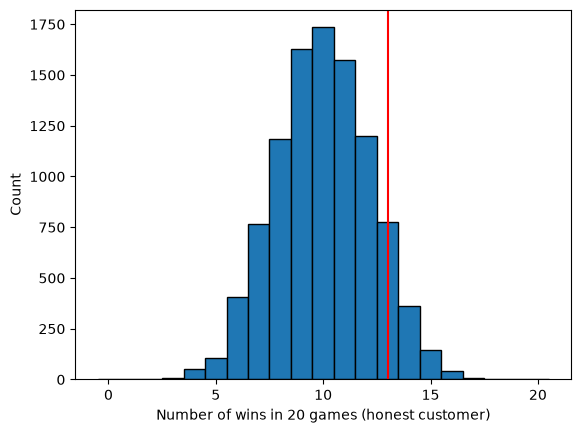

In [6]:
# Answer (c):

### BEGIN SOLUTION
plt.hist(null_dist, edgecolor = "black", bins = np.arange(-0.5, 21, 1));
plt.axvline(obs_stat, color = "red");
plt.xlabel("Number of wins in 20 games (honest customer)");
plt.ylabel("Count");
### END SOLUTION

## Part 5. Step 4: Calculate the p-value

Calculate the p-value and save it in `p_value`. Think about which direction counts as "as or more extreme" for this alternative hypothesis.

In [7]:
# Answer:

### BEGIN SOLUTION REPLACE p_value = ...
p_value = np.mean(np.array(null_dist) >= obs_stat)
### END SOLUTION

p_value

np.float64(0.1337)

## Part 6. Step 5: Make a decision

The casino uses a **1% cutoff**, because accusing a customer of cheating is serious.

**(a)** What do you conclude about the null hypothesis, and what does that mean for the customer?

**(b)** Is your p-value the probability that the customer cheated? If not, what is it?

**(c)** Is the 1% cutoff the probability that the customer cheated? If not, what is it?

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: (a) The p-value is about 0.13, which is not below 1%, so we do not reject the null hypothesis. An honest customer wins 13 or more of 20 games about 1 time in 8, so this is not good evidence of cheating. It does not prove the customer is honest; 20 games are just not enough evidence.

(b) No. It is the probability that an HONEST customer wins 13 or more of 20 games.

(c) No. It is the largest chance the casino is willing to take of accusing a customer who is honest.</font>
<!-- END SOLUTION -->

## Part 7. Many customers

Suppose the casino tests **400 customers**, each after 20 games, with the 1% cutoff, and in fact **none of them is cheating**.

**(a)** About how many of them would the casino accuse of cheating? Explain.

**(b)** Simulate one night of this. Use a for loop over 400 customers. For each customer, simulate their wins with `flip_coins()`, compute that customer's p-value from your `null_dist`, and count how many have a p-value of 0.01 or less in `num_accused`. Also keep track of the largest number of wins any customer had, in `most_wins`. Print both. Run the cell a few times.

**(c)** Your count in (b) is usually smaller than your answer to (a), and it changes from run to run. Why? And what does `most_wins` tell you about accusing the luckiest customer?

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: (a) About 4: the cutoff is the chance of accusing an honest customer, and 1% of 400 is 4.</font>
<!-- END SOLUTION -->

In [8]:
# Answer (b):

### BEGIN SOLUTION
num_accused = 0
most_wins = 0

for customer in range(400):
    wins = flip_coins(20, 0.5)
    customer_p_value = np.mean(np.array(null_dist) >= wins)
    if customer_p_value <= 0.01:
        num_accused = num_accused + 1
    if wins > most_wins:
        most_wins = wins
### END SOLUTION

print(num_accused, most_wins)

3 17


<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: (c) Wins are whole numbers, so a p-value of 0.01 or less needs 16 or more wins, and an honest customer gets 16 or more only about 0.6% of the time, not 1%. So the casino expects about 2.4 accusations, and the actual number varies from night to night. The luckiest of 400 honest customers usually has 16 or 17 wins: on about 9 nights out of 10 at least one honest customer reaches 16 wins and would be accused. Test enough honest people and some will look guilty.</font>
<!-- END SOLUTION -->

## Part 8. What would you tell the manager?

In 3–5 sentences, explain to the casino manager what this analysis shows, and what the casino should do differently if it wants to catch cheaters without accusing honest customers.

<!-- BEGIN SOLUTION REPLACE <font color='red'>**ANSWER**: \n\n</font> -->
<font color='red'>**ANSWER**: Winning 13 of 20 games is not unusual for an honest customer (it happens about 1 time in 8), so there is no good evidence that this customer cheats. If the casino tests many customers, some honest ones will look guilty by chance: with a 1% cutoff, at most about 1% of honest customers tested, and the luckiest one out of many will almost always look suspicious. So the casino should decide its rule before looking at the data, never single out the most extreme customer after the fact and test only them, and gather more evidence (more games) on a suspicious customer before accusing anyone.</font>
<!-- END SOLUTION -->